In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd
import os
python_exec = sys.executable

## change to examples folder

In [2]:
basedir = 'openevolve/examples/symbolic_regression/'
basedir = 'example_symbolic_regression/'
os.chdir(basedir)

## select a problem

In [3]:
## if you change problem id restart the notebook and run all cells again
## available problems:
##   'matsci/MatSci18'
##   'bio_pop_growth/BPG8'   population growth: the LLM is told that x = (t, P) and y = dP_dt
##   'anonymized/BPG8_anon'  same data, evaluator and config as BPG8, but the LLM only sees x0, x1 -> y
problem_id = 'matsci/MatSci18'
problem_id = 'anonymized/BPG8_anon'
problem_id = 'bio_pop_growth/BPG8'
X_test = np.load(f'problems/{problem_id}/X_test_for_eval.npy')
y_test = np.load(f'problems/{problem_id}/y_test_for_eval.npy')

X_train = np.load(f'problems/{problem_id}/X_train_for_eval.npy')
y_train = np.load(f'problems/{problem_id}/y_train_for_eval.npy')

X_test.shape, y_test.shape, X_train.shape, y_train.shape

((500, 2), (500,), (4000, 2), (4000,))

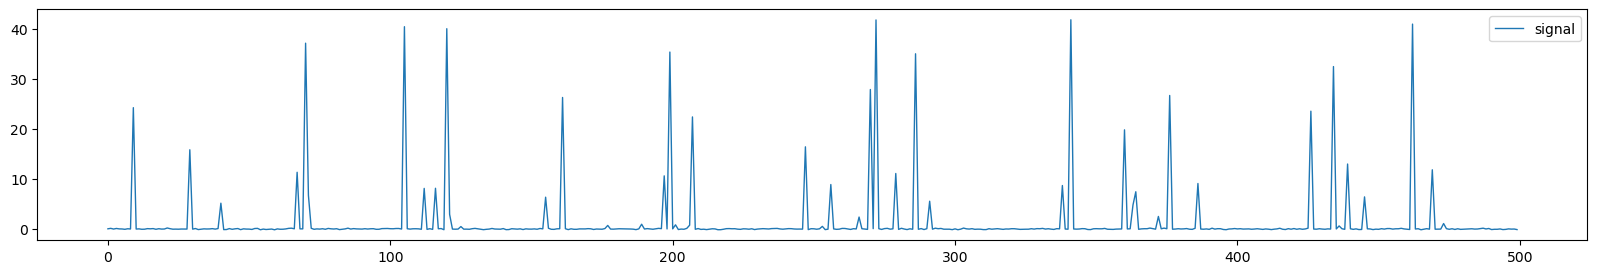

In [4]:
plt.figure(figsize=(20,3))
plt.plot(y_test, lw=1, label='signal')
plt.legend()

## run `evaluation.py` with the initial program

In [5]:
%%bash -s "{python_exec}"  "{problem_id}"

python=$1
problem_id=$2

echo "---- WORKING DIR -----"
echo $basedir
echo "---- PYTHON EXEC -----"
echo $python

$python problems/$problem_id/evaluator.py problems/$problem_id/initial_program.py
#$python problems/$problem_id/evaluator.py problems/$problem_id/openevolve_output/best/best_program.py


---- WORKING DIR -----



---- PYTHON EXEC -----
/Users/fgonza/miniforge3/envs/pytorch/bin/python3.12


Evaluating model: problems/bio_pop_growth/BPG8/initial_program.py
Using NUM_INPUT_FEATURES_EXPECTED 

= 2
Using MODEL_NUM_PARAMS_EXPECTED = 10
Loading X_train from: /Users/fgonza/Documents/research/talk

s/2026/Manizales Workshop/taller-openevolve/openevolve-lab/example_symbolic_regression/problems/bio_

pop_growth/BPG8/X_train_for_eval.npy
Loading y_train from: /Users/fgonza/Documents/research/talks/20

26/Manizales Workshop/taller-openevolve/openevolve-lab/example_symbolic_regression/problems/bio_pop_

growth/BPG8/y_train_for_eval.npy

Evaluation Results:
  combined_score: -1.6110
  negative_mse: -40.

8275


## Optimize the symbolic program function to plot against test data

In [6]:
import importlib

module_evaluator_path = f'problems/{problem_id}/evaluator'
evaluator = importlib.import_module(module_evaluator_path.replace('/','.'))


In [7]:
def get_func(program_path):
  spec = importlib.util.spec_from_file_location("model_program", program_path)
  model_module = importlib.util.module_from_spec(spec)
  spec.loader.exec_module(model_module)
  return model_module.run_search()


def optimize_func_params(func, X=None, y=None):
  from scipy.optimize import minimize
  X = X_train if X is None else X
  y = y_train if y is None else y
  initial_params = np.random.rand(10)

  opt_result = minimize(
      evaluator.objective_function,
      initial_params,
      args=(func, X, y),
      method='BFGS'
  )
  return opt_result.x

In [8]:
initial_program_path = f'problems/{problem_id}/initial_program.py'
best_program_path = f'problems/{problem_id}/openevolve_output/best/best_program.py'

# parameters are fitted on the training data; the error is measured on the test data
initial_program_func        = get_func(initial_program_path)
initial_program_params      = optimize_func_params(initial_program_func)
initial_program_y_test_pred = initial_program_func(X_test, initial_program_params)
initial_program_test_negative_mse = -np.mean((initial_program_y_test_pred - y_test)**2)
print (f'initial program test negative mse {initial_program_test_negative_mse:.6f}')


if os.path.isfile(best_program_path):
  best_program_func        = get_func(best_program_path)
  best_program_params      = optimize_func_params(best_program_func)
  best_program_y_test_pred = best_program_func(X_test, best_program_params)
  best_program_test_negative_mse = -np.mean((best_program_y_test_pred - y_test)**2)
  print (f'best program test negative mse {best_program_test_negative_mse:.6f}')

initial program test negative mse -37.745229
best program test negative mse -0.000172


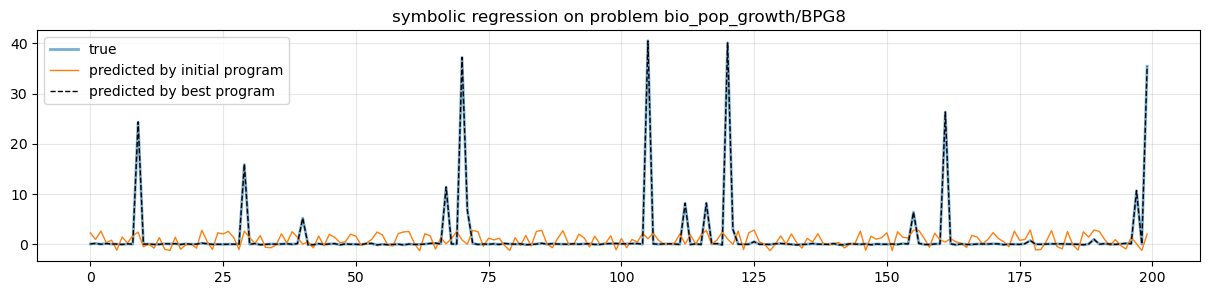

In [9]:
plt.figure(figsize=(15,3))
plt.plot(y_test[:200], color='tab:blue', lw=2, alpha=.6, label='true')
plt.plot(initial_program_y_test_pred[:200], color='tab:orange', lw=1, label='predicted by initial program')
if os.path.isfile(best_program_path):
  plt.plot(best_program_y_test_pred[:200], color='black', lw=1, ls='--', label='predicted by best program')

plt.title(f'symbolic regression on problem {problem_id}')
plt.grid(alpha=.3)
plt.legend()

## Inspect the best program

In [10]:
!cat {best_program_path}

"""
Initial program: A naive linear model for symbolic regression.
This model predicts the output as a linear combination of input variables
or a constant if no input variables are present.
The function is designed for vectorized input (X matrix).

Target output variable: dP_dt (Population growth rate)
Input variables (columns of x): t (Time), P (Population at time t)
"""
import numpy as np

# Input variable mapping for x (columns of the input matrix):
#   x[:, 0]: t (Time)
#   x[:, 1]: P (Population at time t)

# Parameters will be optimized by BFGS outside this function.
# Number of parameters expected by this model: 10.
# Example initialization: params = np.random.rand(10)

# EVOLVE-BLOCK-START

def func(x, params):
    """
    Models population growth rate dP_dt using a non-autonomous logistic-type model.
    Inputs:
        x[:, 0]: t (Time)
        x[:, 1]: P (Population)
    """
    t, P = x[:, 0], x[:, 1]
    # Combines linear, quadratic (logistic), and time-interaction terms
 

## Compare the two versions of BPG8: with and without domain information

`bio_pop_growth/BPG8` and `anonymized/BPG8_anon` share the same data, evaluator and configuration. The only difference is what the LLM sees: in BPG8 the prompt says that the inputs are time `t` and population `P` and that the output is the population growth rate `dP_dt`; in BPG8_anon the variables are just `x0`, `x1` and `y`.

The cells below take the best program found in each run, fit its parameters on the training data and measure the error on the training, test and out-of-distribution (OOD) sets. Since BFGS starts from random parameters, the fit is repeated several times and the best training fit is kept. Note that during evolution the score (`-log10(mse)`) was computed **only on the training data**.

In [11]:
import re

compare_problems = ['bio_pop_growth/BPG8', 'anonymized/BPG8_anon']

# both problems use exactly the same data files
bpg8_dir = 'problems/bio_pop_growth/BPG8'
bpg8_data = {
    split: (np.load(f'{bpg8_dir}/X_{split}_for_eval.npy'), np.load(f'{bpg8_dir}/y_{split}_for_eval.npy'))
    for split in ['train', 'test', 'ood_test']
}


def fit_best_of(func, X, y, n_restarts=5):
  # BFGS from several random starting points, keep the best training fit
  best_params, best_mse = None, np.inf
  for _ in range(n_restarts):
    params = optimize_func_params(func, X, y)
    mse = np.mean((func(X, params) - y)**2)
    if np.isfinite(mse) and mse < best_mse:
      best_params, best_mse = params, mse
  return best_params


def evolve_block(program_path):
  code = open(program_path).read()
  match = re.search(r'# EVOLVE-BLOCK-START\n(.*?)# EVOLVE-BLOCK-END', code, re.S)
  return match.group(1).strip() if match else code


rows, compare_preds = [], {}
for pid in compare_problems:
  path = f'problems/{pid}/openevolve_output/best/best_program.py'
  if not os.path.isfile(path):
    print(f'{pid}: no best program found at {path}')
    continue
  func = get_func(path)
  params = fit_best_of(func, *bpg8_data['train'])
  row = {'problem': pid,
         'parameters used': len(set(re.findall(r'params\[(\d+)\]', evolve_block(path))))}
  for split, (X, y) in bpg8_data.items():
    mse = np.mean((func(X, params) - y)**2)
    row[f'{split} score'] = -np.log10(mse + 1e-9)
  rows.append(row)
  compare_preds[pid] = func(bpg8_data['test'][0], params)

pd.DataFrame(rows).set_index('problem').round(3)

,parameters used,train score,test score,ood_test score
problem,,,,
bio_pop_growth/BPG8,5,3.723,3.729,3.526
anonymized/BPG8_anon,10,3.808,3.823,3.573


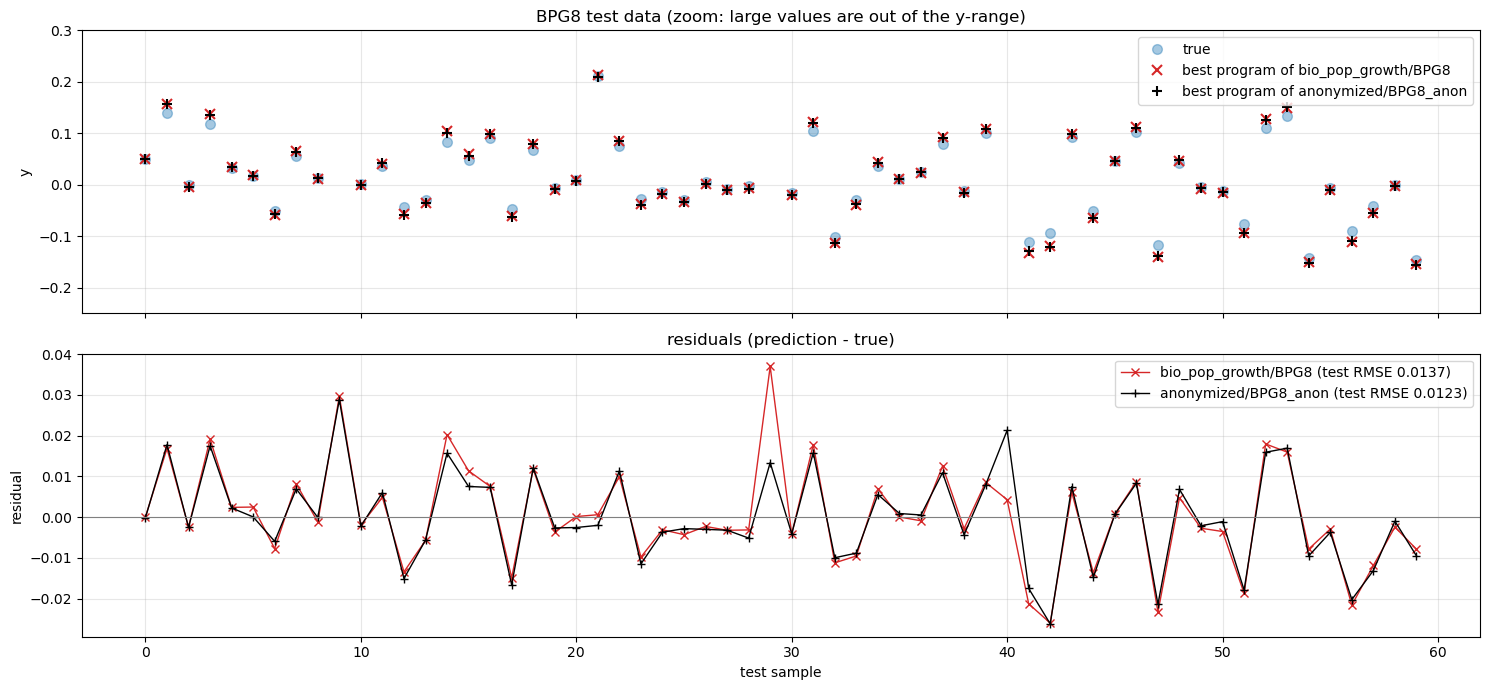

In [12]:
y_true = bpg8_data['test'][1]
styles = {'bio_pop_growth/BPG8': dict(color='tab:red', marker='x'),
          'anonymized/BPG8_anon': dict(color='black', marker='+')}

# the test samples are independent points (not a time series), so they are drawn as markers
zoom = slice(0, 60)            # sample window to inspect
idx = np.arange(len(y_true))[zoom]

fig, axs = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

# (a) zoom on the small values, where the two models differ
axs[0].plot(idx, y_true[zoom], 'o', color='tab:blue', ms=7, alpha=.4, label='true')
for pid, pred in compare_preds.items():
  axs[0].plot(idx, pred[zoom], ls='none', ms=7, mew=1.5, label=f'best program of {pid}', **styles.get(pid, {}))
axs[0].set_ylim(-0.25, 0.3)
axs[0].set_title('BPG8 test data (zoom: large values are out of the y-range)')
axs[0].set_ylabel('y')

# (b) residuals: prediction - true value
for pid, pred in compare_preds.items():
  st = styles.get(pid, {})
  axs[1].plot(idx, (pred - y_true)[zoom], color=st.get('color'), lw=1, marker=st.get('marker'),
              ms=6, label=f'{pid} (test RMSE {np.sqrt(np.mean((pred - y_true)**2)):.4f})')
axs[1].axhline(0, color='gray', lw=.8)
axs[1].set_title('residuals (prediction - true)')
axs[1].set_ylabel('residual')
axs[1].set_xlabel('test sample')

for ax in axs:
  ax.grid(alpha=.3)
  ax.legend(loc='upper right')
plt.tight_layout()

In [13]:
for pid in compare_problems:
  path = f'problems/{pid}/openevolve_output/best/best_program.py'
  if os.path.isfile(path):
    print(f'===== {pid} =====')
    print(evolve_block(path))
    print()

===== bio_pop_growth/BPG8 =====
def func(x, params):
    """
    Models population growth rate dP_dt using a non-autonomous logistic-type model.
    Inputs:
        x[:, 0]: t (Time)
        x[:, 1]: P (Population)
    """
    t, P = x[:, 0], x[:, 1]
    # Combines linear, quadratic (logistic), and time-interaction terms
    return params[0]*P + params[1]*(P**2) + params[2]*t*P + params[3]*t + params[4]

===== anonymized/BPG8_anon =====
def func(x, params):
    """
    Non-linear combination of inputs with polynomial, interaction, and trigonometric terms.
    """
    x0, x1 = x[:, 0], x[:, 1]
    return (
        params[0] * x0 +
        params[1] * x1 +
        params[2] * (x0 ** 2) +
        params[3] * (x1 ** 2) +
        params[4] * (x0 * x1) +
        params[5] * np.sin(x0) +
        params[6] * np.cos(x1) +
        params[7] * np.sin(x1) * x0 +
        params[8] * np.cos(x0) * x1 +
        params[9]
    )

